# Stage 2 — LSTM Bike-Sharing Forecasting

**Task:** Predict the next day's seven variables from the previous seven daily observations. Grid search compares one-layer (Vanilla) and two-layer (Stacked) LSTMs. Select the LSTM configuration using validation performance; evaluate test performance only after the team's finalist choice is fixed.

Load `day.csv`

In [3]:
import pandas as pd

df = pd.read_csv('day.csv')
print('Loaded day.csv:', df.shape)
display(df.head(3))

Loaded day.csv: (731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349


Date indexing and preprocessing

In [4]:
df = df.rename(columns={'dteday': 'date'})
df['date'] = pd.to_datetime(df['date'])
df = df.set_index('date') #make date the new index for this to be a true time series

In [5]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# first 70% of time series is training - can be used to create scaler object
train_limit = int(len(df) * 0.70)

# Log-transform rental counts to reduce skewness and compress large values
log_cnt = np.log(df['cnt'])
log_casual = np.log(df['casual'])
log_registered = np.log(df['registered'])

# Initialize Scalers
scaler_cnt = MinMaxScaler()
scaler_casual = MinMaxScaler()
scaler_registered = MinMaxScaler()

# Fit scalers on training portion only, then transform entire series
scaler_cnt.fit(log_cnt.values[:train_limit].reshape(-1, 1))
scaled_log_cnt = scaler_cnt.transform(log_cnt.values.reshape(-1, 1))

scaler_casual.fit(log_casual.values[:train_limit].reshape(-1, 1))
scaled_log_casual = scaler_casual.transform(log_casual.values.reshape(-1, 1))

scaler_registered.fit(log_registered.values[:train_limit].reshape(-1, 1))
scaled_log_registered = scaler_registered.transform(log_registered.values.reshape(-1, 1))

In [6]:
# Initialize Scalers for temp and atemp
scaler_temp = MinMaxScaler()
scaler_atemp = MinMaxScaler()

# Fit on training portion only, then transform
scaler_temp.fit(df['temp'].values[:train_limit].reshape(-1, 1))
scaled_temp = scaler_temp.transform(df['temp'].values.reshape(-1, 1))

scaler_atemp.fit(df['atemp'].values[:train_limit].reshape(-1, 1))
scaled_atemp = scaler_atemp.transform(df['atemp'].values.reshape(-1, 1))

In [7]:
# Initialize Scalers for windspeed and hum
scaler_windspeed = MinMaxScaler()
scaler_hum = MinMaxScaler()

# Fit on training portion only, then transform
scaler_windspeed.fit(df['windspeed'].values[:train_limit].reshape(-1, 1))
scaled_windspeed = scaler_windspeed.transform(df['windspeed'].values.reshape(-1, 1))

scaler_hum.fit(df['hum'].values[:train_limit].reshape(-1, 1))
scaled_hum = scaler_hum.transform(df['hum'].values.reshape(-1, 1))

##Multivariate sliding windows and chronological splits


In [8]:
# 1. Combine our 7 parallel scaled features into a single 2D array of shape (731, 7)
# Note: ensuring all features are reshaped properly to 1D before column_stack
multivariate_data = np.column_stack([
    scaled_log_cnt.flatten(),
    scaled_log_casual.flatten(),
    scaled_log_registered.flatten(),
    scaled_temp.flatten(),
    scaled_atemp.flatten(),
    scaled_windspeed.flatten(),
    scaled_hum.flatten()
])

print("Combined multivariate data shape:", multivariate_data.shape)

Combined multivariate data shape: (731, 7)


In [9]:
# 2. Define a function to split our parallel sequences into sliding window samples predicting all variables
def split_multivariate_sequences(sequences, lookback, horizon=1):
    X, y = [], []
    for i in range(len(sequences)):
        # find the end of this pattern
        end_ix = i + lookback
        out_end_ix = end_ix + horizon - 1
        # check if we are beyond the dataset
        if out_end_ix >= len(sequences):
            break
        # gather input (past history) and output (future values for all 7 variables)
        seq_x, seq_y = sequences[i:end_ix, :], sequences[end_ix:out_end_ix + 1, :]
        X.append(seq_x)
        y.append(seq_y)
    return np.array(X), np.array(y)

# Define parameters
L = 7  # Lookback window (7 days of history)
h = 1  # Horizon (predicting 1 day into the future)

# 3. Create the dataset
X, y = split_multivariate_sequences(multivariate_data, lookback=L, horizon=h)

print("X shape (samples, lookback, features):", X.shape)
print("y shape (samples, horizon, features):", y.shape)

X shape (samples, lookback, features): (724, 7, 7)
y shape (samples, horizon, features): (724, 1, 7)


In [10]:
# Calculate the split indices
total_samples = len(X)
train_end = int(total_samples * 0.70)       # 70% for Training
val_end = int(total_samples * 0.85)         # 15% for Validation, remaining 15% for Test

# Split inputs (X)
X_train, X_val, X_test = X[:train_end], X[train_end:val_end], X[val_end:]

# Split targets (y)
y_train, y_val, y_test = y[:train_end], y[train_end:val_end], y[val_end:]

print(f"Total sliding window samples: {total_samples}")
print(f"Train set shape:      X={X_train.shape}, y={y_train.shape}")
print(f"Validation set shape: X={X_val.shape}, y={y_val.shape}")
print(f"Test set shape:       X={X_test.shape}, y={y_test.shape}")

Total sliding window samples: 724
Train set shape:      X=(506, 7, 7), y=(506, 1, 7)
Validation set shape: X=(109, 7, 7), y=(109, 1, 7)
Test set shape:       X=(109, 7, 7), y=(109, 1, 7)


---
# LSTM

## 1. LSTM inputs and architecture

We use the existing three-dimensional windows `(samples, 7 days, 7 features)` directly. This is a multivariate, one-step-ahead sequence-to-vector forecasting problem: one past sequence predicts seven next-day variables. Unlike the MLP, we do **not** flatten the LSTM inputs. We flatten only the target shape from `(samples, 1, 7)` to `(samples, 7)`.

The LSTM maintains a cell state and uses input, forget, and output gates to control information across the time steps. We'll compare a **Vanilla LSTM** (one recurrent layer) with a **Stacked LSTM** (two recurrent layers, with `return_sequences=True` on the first). A dropout layer helps regularize the model; the final linear Dense layer predicts continuous values.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import json
import joblib
from pathlib import Path
from itertools import product
from time import perf_counter
from sklearn.metrics import mean_absolute_error, mean_squared_error
from IPython.display import display

# The same seven features and feature order as the main notebook
FEATURES = ['cnt', 'casual', 'registered',
            'temp', 'atemp', 'windspeed', 'hum']
# Use original 3D windows; do not flatten the inputs
X_train_lstm = np.asarray(X_train, dtype=np.float32)
X_val_lstm = np.asarray(X_val, dtype=np.float32)
X_test_lstm = np.asarray(X_test, dtype=np.float32)

# Flatten only the one-day, seven-variable targets
Y_train_lstm = y_train.reshape(len(y_train), -1).astype(np.float32)
Y_val_lstm = y_val.reshape(len(y_val), -1).astype(np.float32)
Y_test_lstm = y_test.reshape(len(y_test), -1).astype(np.float32)


def inverse_cnt_lstm(values):
    # Inverse MinMax, then inverse natural log (np.exp)
    log_counts = scaler_cnt.inverse_transform(
        np.asarray(values).reshape(-1, 1)
    )
    return np.exp(log_counts).ravel()

# Use date index already constructed in the shared pipeline
all_target_dates = df.index[L + h - 1:]
val_dates_lstm = all_target_dates[train_end:val_end]
test_dates_lstm = all_target_dates[val_end:]

# Local output folder
LSTM_DIR = Path('stage2_lstm_artifacts')
LSTM_DIR.mkdir(parents=True, exist_ok=True)

print('Train:', X_train_lstm.shape, Y_train_lstm.shape)
print('Validation:', X_val_lstm.shape, Y_val_lstm.shape)
print('Test:', X_test_lstm.shape, Y_test_lstm.shape)

assert X_train_lstm.ndim == 3 and X_train_lstm.shape[1:] == (L, len(FEATURES))
assert Y_train_lstm.shape[1] == len(FEATURES)
assert len(test_dates_lstm) == len(X_test_lstm)

Train: (506, 7, 7) (506, 7)
Validation: (109, 7, 7) (109, 7)
Test: (109, 7, 7) (109, 7)


## 2. Grid search — architecture and hyperparameters

**Search space (defined before running the trials):** Architecture ∈ {Vanilla, Stacked}; LSTM units ∈ {16, 32}; Adam learning rate ∈ {0.001, 0.0005}. This produces **8 trials**. All trials use a batch size of 32, dropout 0.2, MSE loss, MAE tracking, a 200-epoch budget, and early stopping after 25 epochs without improving validation loss.

The model's optimizer uses gradient clipping (`clipnorm=1.0`) to limit large updates. Each trial is ranked by **lowest validation MSE averaged across all seven scaled outputs**, matching the primary loss in the existing MLP. Validation rental-count MAE/RMSE are additionally reported to support cross-model comparison. The test set is not consulted during tuning.

In [ ]:
EPOCHS = 200
PATIENCE = 25
BATCH_SIZE = 32
DROPOUT_RATE = 0.2
SEED = 42

ARCHITECTURES = ["Vanilla", "Stacked"]
UNITS_GRID = [16, 32]
LR_GRID = [0.001, 0.0005]


def build_lstm(architecture, units, learning_rate):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(L, len(FEATURES)))
    ])
    if architecture == "Vanilla":
        model.add(tf.keras.layers.LSTM(units))
    elif architecture == "Stacked":
        model.add(tf.keras.layers.LSTM(units, return_sequences=True))
        model.add(tf.keras.layers.LSTM(units))
    else:
        raise ValueError(f"Unsupported architecture: {architecture}")
    model.add(tf.keras.layers.Dropout(DROPOUT_RATE))
    model.add(tf.keras.layers.Dense(len(FEATURES), activation="linear"))
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate, clipnorm=1.0),
        loss="mse", metrics=["mae"]
    )
    return model

trial_rows = []
selected_val_mse = float("inf")
selected_history = None
configs = list(product(ARCHITECTURES, UNITS_GRID, LR_GRID))

for trial_id, (architecture, units, learning_rate) in enumerate(configs, 1):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    candidate = build_lstm(architecture, units, learning_rate)
    callback = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=PATIENCE, restore_best_weights=True
    )

    start = perf_counter()
    history = candidate.fit(
        X_train_lstm, Y_train_lstm,
        validation_data=(X_val_lstm, Y_val_lstm),
        epochs=EPOCHS, batch_size=BATCH_SIZE,
        shuffle=False, callbacks=[callback], verbose=0
    )
    train_seconds = perf_counter() - start

    val_mse, val_mae = candidate.evaluate(X_val_lstm, Y_val_lstm, verbose=0)
    candidate.predict(X_val_lstm, verbose=0)  # inference warm-up
    start = perf_counter()
    val_prediction = candidate.predict(X_val_lstm, verbose=0)
    val_infer_seconds = perf_counter() - start
    actual_val_cnt = inverse_cnt_lstm(Y_val_lstm[:, 0])
    pred_val_cnt = inverse_cnt_lstm(val_prediction[:, 0])
    val_cnt_mae = mean_absolute_error(actual_val_cnt, pred_val_cnt)
    val_cnt_rmse = np.sqrt(mean_squared_error(actual_val_cnt, pred_val_cnt))

    row = {
        "Trial": trial_id,
        "Architecture": architecture,
        "LSTM Units": units,
        "Learning Rate": learning_rate,
        "Batch Size": BATCH_SIZE,
        "Val MSE (scaled, all outputs)": float(val_mse),
        "Val MAE (scaled, all outputs)": float(val_mae),
        "Val cnt MAE (rentals)": float(val_cnt_mae),
        "Val cnt RMSE (rentals)": float(val_cnt_rmse),
        "Best Epoch": int(np.argmin(history.history["val_loss"]) + 1),
        "Epochs Trained": len(history.history["loss"]),
        "Parameters": int(candidate.count_params()),
        "Training Time (s)": train_seconds,
        "Validation Inference Time (s)": val_infer_seconds
    }
    trial_rows.append(row)
    print(f"Trial {trial_id}/8: {architecture}, {units} units, lr={learning_rate} "
          f"-> validation MSE={val_mse:.6f}, cnt RMSE={val_cnt_rmse:.1f}")

    if val_mse < selected_val_mse:
        selected_val_mse = float(val_mse)
        selected_history = {key: [float(v) for v in vals]
                            for key, vals in history.history.items()}

lstm_trials = pd.DataFrame(trial_rows).sort_values(
    "Val MSE (scaled, all outputs)"
).reset_index(drop=True)
selected_row = lstm_trials.iloc[0]

display(lstm_trials)
print("\nSelected model:")
print(selected_row[["Architecture", "LSTM Units", "Learning Rate",
                    "Batch Size", "Best Epoch", "Parameters",
                    "Val MSE (scaled, all outputs)"]].to_string())
lstm_model.summary()

Trial 1/8: Vanilla, 16 units, lr=0.001 -> validation MSE=0.006971, cnt RMSE=958.7
Trial 2/8: Vanilla, 16 units, lr=0.0005 -> validation MSE=0.007093, cnt RMSE=1006.5
Trial 3/8: Vanilla, 32 units, lr=0.001 -> validation MSE=0.006487, cnt RMSE=945.3
Trial 4/8: Vanilla, 32 units, lr=0.0005 -> validation MSE=0.007130, cnt RMSE=1082.7
Trial 5/8: Stacked, 16 units, lr=0.001 -> validation MSE=0.008598, cnt RMSE=1137.5
Trial 6/8: Stacked, 16 units, lr=0.0005 -> validation MSE=0.008720, cnt RMSE=1217.0
Trial 7/8: Stacked, 32 units, lr=0.001 -> validation MSE=0.007323, cnt RMSE=1013.0
Trial 8/8: Stacked, 32 units, lr=0.0005 -> validation MSE=0.008796, cnt RMSE=1293.4


,Trial,Architecture,LSTM Units,Learning Rate,Batch Size,"Val MSE (scaled, all outputs)","Val MAE (scaled, all outputs)",Val cnt MAE (rentals),Val cnt RMSE (rentals),Best Epoch,Epochs Trained,Parameters,Training Time (s),Validation Inference Time (s)
0,3,Vanilla,32,0.0010,32,0.006487,0.060811,760.646851,945.349208,199,200,5351,42.495542,0.118366
1,1,Vanilla,16,0.0010,32,0.006971,0.063464,776.957581,958.681386,123,148,1655,34.948641,0.084212
2,2,Vanilla,16,0.0005,32,0.007093,0.063979,830.040405,1006.523317,179,200,1655,42.666511,0.130493
3,4,Vanilla,32,0.0005,32,0.007130,0.065088,936.178711,1082.722725,198,200,5351,41.703611,0.139939
4,7,Stacked,32,0.0010,32,0.007323,0.066314,844.462646,1013.048586,131,156,13671,38.123140,0.082666
5,5,Stacked,16,0.0010,32,0.008598,0.073651,987.966309,1137.454230,98,123,3767,29.752375,0.092417
6,6,Stacked,16,0.0005,32,0.008720,0.074211,1059.533691,1216.966516,179,200,3767,48.026856,0.128054
7,8,Stacked,32,0.0005,32,0.008796,0.074676,1110.698242,1293.437764,23,48,13671,13.538401,0.083351



Selected model:
Architecture                      Vanilla
LSTM Units                             32
Learning Rate                       0.001
Batch Size                             32
Best Epoch                            199
Parameters                           5351
Val MSE (scaled, all outputs)    0.006487


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,055 (62.72 KB)

 Trainable params: 5,351 (20.90 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 10,704 (41.82 KB)

## 3. Grid-search results and learning curves

The trials table and validation-MSE plot document the eight tested configurations. Training and validation MSE/MAE curves for the **selected** model help evaluate convergence and possible overfitting. A falling training loss accompanied by a sustained rise in validation loss suggests overfitting. The saved model restores the epoch with the lowest validation MSE.

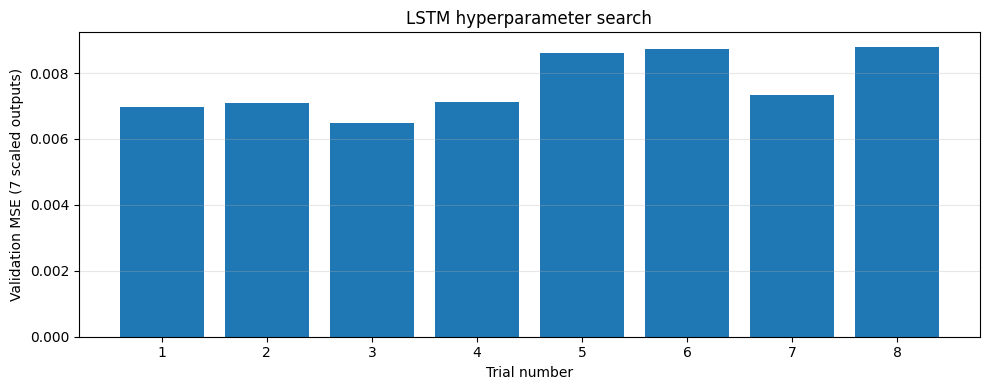

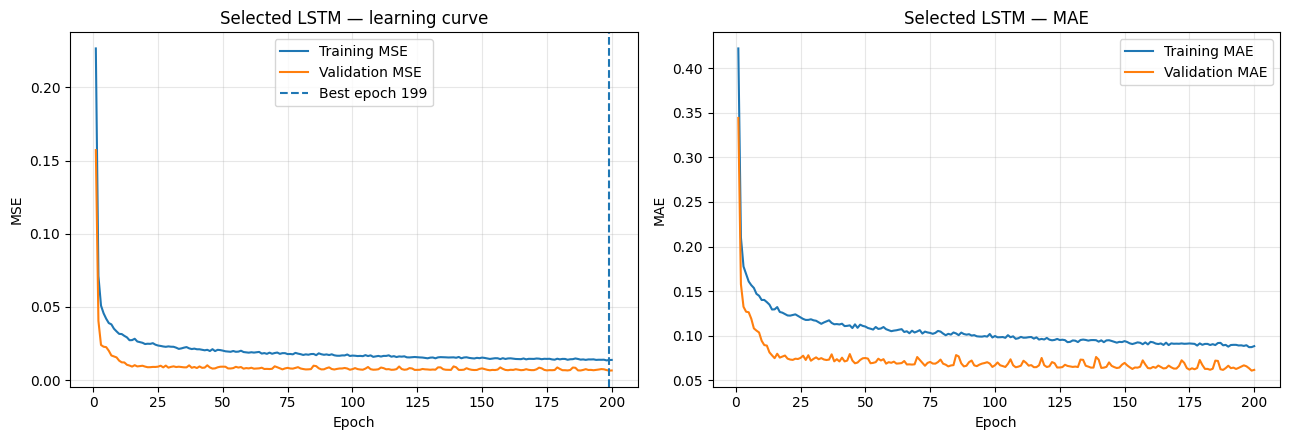

Selected model best epoch: 199
Epochs trained: 200
Training MSE at selected epoch: 0.013713
Validation MSE at selected epoch: 0.006487


In [ ]:
trial_order = lstm_trials.sort_values("Trial")
plt.figure(figsize=(10, 4))
plt.bar(trial_order["Trial"].astype(str), trial_order["Val MSE (scaled, all outputs)"])
plt.xlabel("Trial number")
plt.ylabel("Validation MSE (7 scaled outputs)")
plt.title("LSTM hyperparameter search")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(LSTM_DIR / "lstm_grid_search.png", dpi=180)
plt.show()

loss_train = np.asarray(selected_history["loss"])
loss_val = np.asarray(selected_history["val_loss"])
mae_train = np.asarray(selected_history["mae"])
mae_val = np.asarray(selected_history["val_mae"])
selected_best_epoch = int(np.argmin(loss_val) + 1)
xs = np.arange(1, len(loss_train) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(xs, loss_train, label="Training MSE")
axes[0].plot(xs, loss_val, label="Validation MSE")
axes[0].axvline(selected_best_epoch, linestyle="--", label=f"Best epoch {selected_best_epoch}")
axes[0].set(xlabel="Epoch", ylabel="MSE", title="Selected LSTM — learning curve")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].plot(xs, mae_train, label="Training MAE")
axes[1].plot(xs, mae_val, label="Validation MAE")
axes[1].set(xlabel="Epoch", ylabel="MAE", title="Selected LSTM — MAE")
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(LSTM_DIR / "lstm_learning_curves.png", dpi=180)
plt.show()
print("Selected model best epoch:", selected_best_epoch)
print("Epochs trained:", len(loss_train))
print("Training MSE at selected epoch:", round(float(loss_train[selected_best_epoch-1]), 6))
print("Validation MSE at selected epoch:", round(float(loss_val[selected_best_epoch-1]), 6))

## 4. Validation performance and baselines

The model must be compared with the naive (last day), seasonal naive (seven days earlier), and mean baselines on **the same validation samples**. Rental-count errors are reported in original units by reversing the MinMax scaling and natural-log transform. Training/inference time and parameter counts are included for the team's Stage 2 comparison. Inference timing uses a warm-up and measures a single batched prediction call; compare timing only on the same hardware.

Validation comparison — original-scale daily bike rentals


,Model,MAE (rentals),RMSE (rentals)
0,Naive,738.320801,1059.721603
1,Seasonal Naive,853.321106,1119.552980
2,Mean,3329.241211,3439.297893
3,LSTM,760.646851,945.349208



Selected model parameters: 5351
Training time (s): 42.496
Validation inference time (s): 0.1184


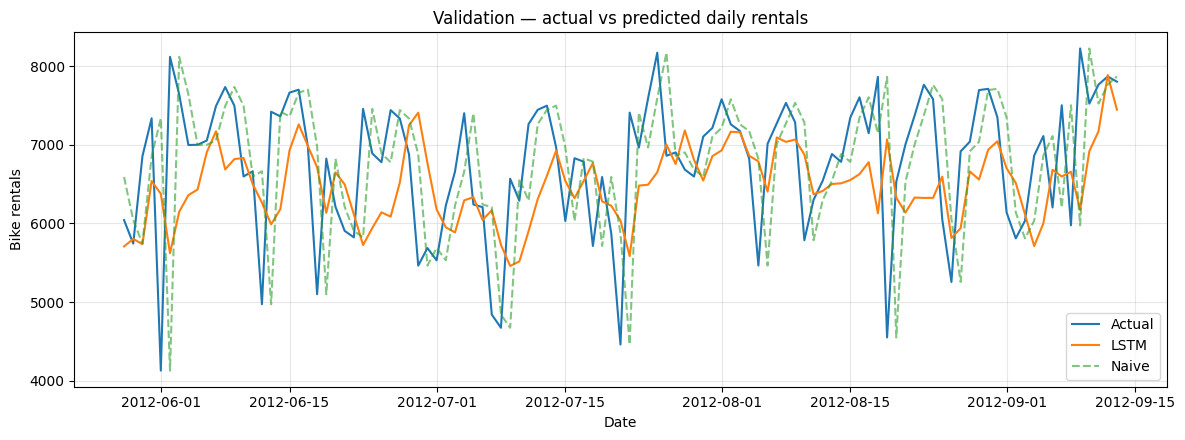

In [ ]:
def evaluate_rental_baselines(X_data, y_data, model_pred):
    actual = inverse_cnt_lstm(y_data[:, 0])
    predictions = {
        "Naive": inverse_cnt_lstm(X_data[:, -1, 0]),
        "Seasonal Naive": inverse_cnt_lstm(X_data[:, 0, 0]),
        "Mean": inverse_cnt_lstm(np.full(len(y_data), Y_train_lstm[:, 0].mean())),
        "LSTM": inverse_cnt_lstm(model_pred[:, 0])
    }
    rows = []
    for label, predicted in predictions.items():
        rows.append({
            "Model": label,
            "MAE (rentals)": mean_absolute_error(actual, predicted),
            "RMSE (rentals)": np.sqrt(mean_squared_error(actual, predicted))
        })
    return pd.DataFrame(rows), actual, predictions

validation_predictions = lstm_model.predict(X_val_lstm, verbose=0)
validation_metrics, val_actual, val_series = evaluate_rental_baselines(
    X_val_lstm, Y_val_lstm, validation_predictions
)
print("Validation comparison — original-scale daily bike rentals")
display(validation_metrics)
print("\nSelected model parameters:", lstm_model.count_params())
print("Training time (s):", round(float(selected_row["Training Time (s)"]), 3))
print("Validation inference time (s):",
      round(float(selected_row["Validation Inference Time (s)"]), 4))

plt.figure(figsize=(12, 4.5))
plt.plot(val_dates_lstm, val_actual, label="Actual")
plt.plot(val_dates_lstm, val_series["LSTM"], label="LSTM")
plt.plot(val_dates_lstm, val_series["Naive"], label="Naive", linestyle="--", alpha=0.6)
plt.title("Validation — actual vs predicted daily rentals")
plt.xlabel("Date")
plt.ylabel("Bike rentals")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(LSTM_DIR / "lstm_validation_predictions.png", dpi=180)
plt.show()

## 5. Final held-out test evaluation

Use the test split to report performance **only once the team's finalist/model-selection decision has been frozen using validation results**. This cell compares the selected LSTM with the same three baselines using rental-count MAE and RMSE, records test inference time, and plots actual versus predicted rentals. No further hyperparameter tuning should use these test scores.

Test comparison — original-scale daily bike rentals


,Model,MAE (rentals),RMSE (rentals)
0,Naive,934.467957,1364.928890
1,Seasonal Naive,1380.091797,1969.521579
2,Mean,2580.057129,2893.103610
3,LSTM,1112.504761,1402.151695


7-output scaled test MSE: 0.024642
7-output scaled test MAE: 0.090437
Test inference (109 samples expected): 0.1158s
Inference per sample: 1.062 ms


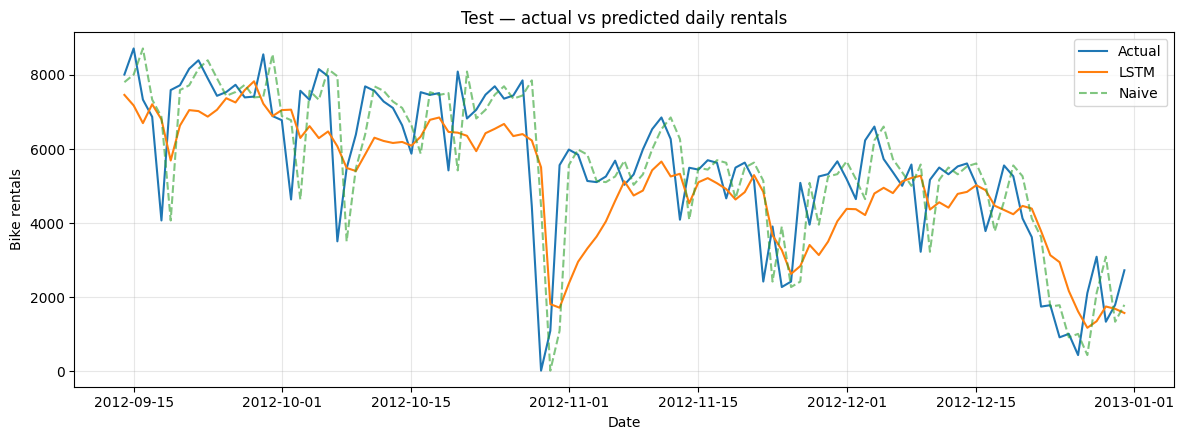

In [ ]:
test_mse_scaled, test_mae_scaled = lstm_model.evaluate(
    X_test_lstm, Y_test_lstm, verbose=0
)
lstm_model.predict(X_test_lstm, verbose=0)  # warm-up
start = perf_counter()
test_prediction = lstm_model.predict(X_test_lstm, verbose=0)
test_inference_seconds = perf_counter() - start

test_metrics, test_actual, test_series = evaluate_rental_baselines(
    X_test_lstm, Y_test_lstm, test_prediction
)
print("Test comparison — original-scale daily bike rentals")
display(test_metrics)
print(f"7-output scaled test MSE: {test_mse_scaled:.6f}")
print(f"7-output scaled test MAE: {test_mae_scaled:.6f}")
print(f"Test inference (109 samples expected): {test_inference_seconds:.4f}s")
print(f"Inference per sample: {1000 * test_inference_seconds / len(X_test_lstm):.3f} ms")

plt.figure(figsize=(12, 4.5))
plt.plot(test_dates_lstm, test_actual, label="Actual")
plt.plot(test_dates_lstm, test_series["LSTM"], label="LSTM")
plt.plot(test_dates_lstm, test_series["Naive"], label="Naive", linestyle="--", alpha=0.6)
plt.title("Test — actual vs predicted daily rentals")
plt.xlabel("Date")
plt.ylabel("Bike rentals")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(LSTM_DIR / "lstm_test_predictions.png", dpi=180)
plt.show()

## LSTM for 60 epochs for comparison to other models

This experiment uses a single-layer LSTM with the same hyperparameter search space as the GRU model to provide a more consistent comparison between recurrent architectures.

Grid search evaluates 16 configurations using LSTM units, dropout, learning rate, and batch size. Each trial has a maximum of 60 epochs and uses early stopping with patience 10.

The original seven-day sliding windows, one-day prediction horizon, seven output variables, chronological splits, and training-fitted scaling are retained.

The model is selected using validation MSE. Original-scale rental-count MAE/RMSE, trainable parameters, training time, and inference time are reported.

The earlier 200-epoch experiment is preserved separately.


In [11]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from itertools import product
from time import perf_counter
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Use the same input and output shapes as the GRU/RNN
lstm60_steps = X_train.shape[1]
lstm60_features = X_train.shape[2]
lstm60_horizon = y_train.shape[1]
lstm60_outputs = y_train.shape[2]

# Identical search space to the GRU
lstm60_search_space = {
    "units": [32, 64],
    "dropout": [0.0, 0.1, 0.2],
    "learning_rate": [0.01, 0.001, 0.0001],
    "batch_size": [16, 32, 64]
}

lstm60_max_epochs = 60
lstm60_patience = 10
lstm60_seed = 42

lstm60_combinations = list(product(
    lstm60_search_space["units"],
    lstm60_search_space["dropout"],
    lstm60_search_space["learning_rate"],
    lstm60_search_space["batch_size"]
))

print("Total grid-search trials:", len(lstm60_combinations))
print("Training shape:", X_train.shape, y_train.shape)
print("Validation shape:", X_val.shape, y_val.shape)
print("Test shape:", X_test.shape, y_test.shape)


# Single-layer LSTM, matching the GRU model structure
def build_lstm60(units, dropout, learning_rate):

    model = tf.keras.Sequential([
        tf.keras.layers.Input(
            shape=(lstm60_steps, lstm60_features)
        ),
        tf.keras.layers.LSTM(
            units=units,
            activation="tanh",
            dropout=dropout
        ),
        tf.keras.layers.Dense(
            lstm60_horizon * lstm60_outputs
        ),
        tf.keras.layers.Reshape(
            (lstm60_horizon, lstm60_outputs)
        )
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="mse",
        metrics=["mae"]
    )

    return model


# Reverse scaling to obtain original daily rental counts
def inverse_cnt60(values):
    log_cnt = scaler_cnt.inverse_transform(
        np.asarray(values).reshape(-1, 1)
    )
    return np.exp(log_cnt).ravel()


Total grid-search trials: 54
Training shape: (506, 7, 7) (506, 1, 7)
Validation shape: (109, 7, 7) (109, 1, 7)
Test shape: (109, 7, 7) (109, 1, 7)


In [12]:

lstm60_results = []
lstm60_best_val_mse = float("inf")
lstm60_best_config = None
lstm60_best_weights = None
lstm60_best_history = None

lstm60_hpo_start = perf_counter()

for trial, (units, dropout, lr, batch_size) in enumerate(
    lstm60_combinations, start=1
):

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(lstm60_seed)

    candidate60 = build_lstm60(units, dropout, lr)

    early_stop60 = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=lstm60_patience,
        restore_best_weights=True
    )

    start = perf_counter()

    history60 = candidate60.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=lstm60_max_epochs,
        batch_size=batch_size,
        shuffle=False,
        callbacks=[early_stop60],
        verbose=0
    )

    training_time = perf_counter() - start

    # Validation MSE/MAE across all seven outputs
    val_mse, val_mae = candidate60.evaluate(
        X_val, y_val, verbose=0
    )

    # Measure validation inference after warm-up
    candidate60.predict(X_val, verbose=0)

    start = perf_counter()
    val_prediction = candidate60.predict(
        X_val, verbose=0
    )
    inference_time = perf_counter() - start

    # Evaluate total rental counts in original units
    actual_cnt = inverse_cnt60(y_val[:, 0, 0])
    pred_cnt = inverse_cnt60(val_prediction[:, 0, 0])

    cnt_mae = mean_absolute_error(actual_cnt, pred_cnt)
    cnt_rmse = np.sqrt(mean_squared_error(
        actual_cnt, pred_cnt
    ))

    best_epoch = int(
        np.argmin(history60.history["val_loss"]) + 1
    )

    lstm60_results.append({
        "Trial": trial,
        "Units": units,
        "Dropout": dropout,
        "Learning Rate": lr,
        "Batch Size": batch_size,
        "Validation MSE": float(val_mse),
        "Validation MAE": float(val_mae),
        "CNT MAE (rentals)": float(cnt_mae),
        "CNT RMSE (rentals)": float(cnt_rmse),
        "Best Epoch": best_epoch,
        "Epochs Trained": len(history60.history["loss"]),
        "Parameters": candidate60.count_params(),
        "Training Time (s)": training_time,
        "Inference Time (s)": inference_time
    })

    print(
        f"Trial {trial}/16 | "
        f"Units={units}, Dropout={dropout}, "
        f"LR={lr}, Batch={batch_size} | "
        f"Val MSE={val_mse:.6f}"
    )

    # Select model using validation data only
    if val_mse < lstm60_best_val_mse:
        lstm60_best_val_mse = float(val_mse)

        lstm60_best_config = {
            "units": units,
            "dropout": dropout,
            "learning_rate": lr,
            "batch_size": batch_size
        }

        lstm60_best_weights = [
            w.copy() for w in candidate60.get_weights()
        ]

        lstm60_best_history = {
            key: list(values)
            for key, values in history60.history.items()
        }


lstm60_total_hpo_time = perf_counter() - lstm60_hpo_start

# Display grid-search results
lstm60_trials = pd.DataFrame(lstm60_results)
lstm60_trials = lstm60_trials.sort_values(
    "Validation MSE"
).reset_index(drop=True)

print("\nGRID-SEARCH RESULTS")
display(lstm60_trials)

# Rebuild the best model and restore its trained weights
lstm60_model = build_lstm60(
    units=lstm60_best_config["units"],
    dropout=lstm60_best_config["dropout"],
    learning_rate=lstm60_best_config["learning_rate"]
)

lstm60_model.set_weights(lstm60_best_weights)

lstm60_best_row = lstm60_trials.iloc[0]

print("\nBEST LSTM CONFIGURATION")
print(lstm60_best_config)
print("Best epoch:", int(lstm60_best_row["Best Epoch"]))
print("Validation MSE:", lstm60_best_val_mse)
print("Parameters:", lstm60_model.count_params())
print("Selected trial training time:",
      round(lstm60_best_row["Training Time (s)"], 3), "s")
print("Total HPO time:",
      round(lstm60_total_hpo_time, 3), "s")

lstm60_model.summary()


Trial 1/16 | Units=32, Dropout=0.0, LR=0.01, Batch=16 | Val MSE=0.011105
Trial 2/16 | Units=32, Dropout=0.0, LR=0.01, Batch=32 | Val MSE=0.008877
Trial 3/16 | Units=32, Dropout=0.0, LR=0.01, Batch=64 | Val MSE=0.006968
Trial 4/16 | Units=32, Dropout=0.0, LR=0.001, Batch=16 | Val MSE=0.009364
Trial 5/16 | Units=32, Dropout=0.0, LR=0.001, Batch=32 | Val MSE=0.007824
Trial 6/16 | Units=32, Dropout=0.0, LR=0.001, Batch=64 | Val MSE=0.008760
Trial 7/16 | Units=32, Dropout=0.0, LR=0.0001, Batch=16 | Val MSE=0.013240
Trial 8/16 | Units=32, Dropout=0.0, LR=0.0001, Batch=32 | Val MSE=0.018876
Trial 9/16 | Units=32, Dropout=0.0, LR=0.0001, Batch=64 | Val MSE=0.024310
Trial 10/16 | Units=32, Dropout=0.1, LR=0.01, Batch=16 | Val MSE=0.011804
Trial 11/16 | Units=32, Dropout=0.1, LR=0.01, Batch=32 | Val MSE=0.010734
Trial 12/16 | Units=32, Dropout=0.1, LR=0.01, Batch=64 | Val MSE=0.009671
Trial 13/16 | Units=32, Dropout=0.1, LR=0.001, Batch=16 | Val MSE=0.010649
Trial 14/16 | Units=32, Dropout=0.1, 

,Trial,Units,Dropout,Learning Rate,Batch Size,Validation MSE,Validation MAE,CNT MAE (rentals),CNT RMSE (rentals),Best Epoch,Epochs Trained,Parameters,Training Time (s),Inference Time (s)
0,28,64,0.0,0.0100,16,0.006613,0.059325,852.416504,1126.051182,47,57,18887,17.966469,0.083127
1,3,32,0.0,0.0100,64,0.006968,0.063591,923.380411,1101.204672,39,49,5351,8.972337,0.081926
2,30,64,0.0,0.0100,64,0.006971,0.063740,831.288364,989.138450,29,39,18887,6.893229,0.087687
3,33,64,0.0,0.0010,64,0.007108,0.064692,829.839011,968.778608,60,60,18887,10.255533,0.089138
4,32,64,0.0,0.0010,32,0.007358,0.064733,823.142896,971.951630,40,50,18887,11.038538,0.078190
5,29,64,0.0,0.0100,32,0.007713,0.065065,744.930476,970.693593,20,30,18887,6.384257,0.142346
6,5,32,0.0,0.0010,32,0.007824,0.068302,1153.120955,1318.423797,60,60,5351,13.618471,0.094286
7,39,64,0.1,0.0100,64,0.007858,0.067742,1043.124969,1209.994117,24,34,18887,6.742653,0.082957
8,34,64,0.0,0.0001,16,0.007928,0.068526,896.227656,1026.202180,60,60,18887,17.242810,0.084744
9,31,64,0.0,0.0010,16,0.008429,0.066552,666.690542,918.308693,13,23,18887,8.286708,0.084366



BEST LSTM CONFIGURATION
{'units': 64, 'dropout': 0.0, 'learning_rate': 0.01, 'batch_size': 16}
Best epoch: 47
Validation MSE: 0.006613102741539478
Parameters: 18887
Selected trial training time: 17.966 s
Total HPO time: 598.894 s


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 64)             │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           455 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 1, 7)           │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,887 (73.78 KB)

 Trainable params: 18,887 (73.78 KB)

 Non-trainable params: 0 (0.00 B)

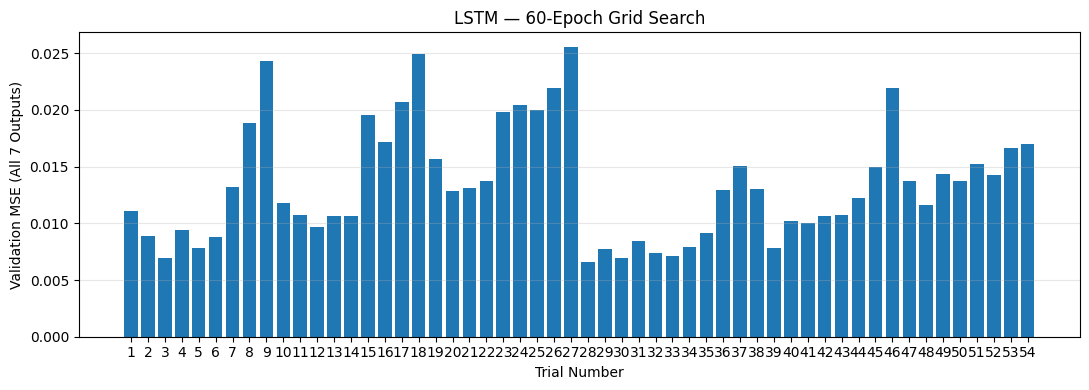

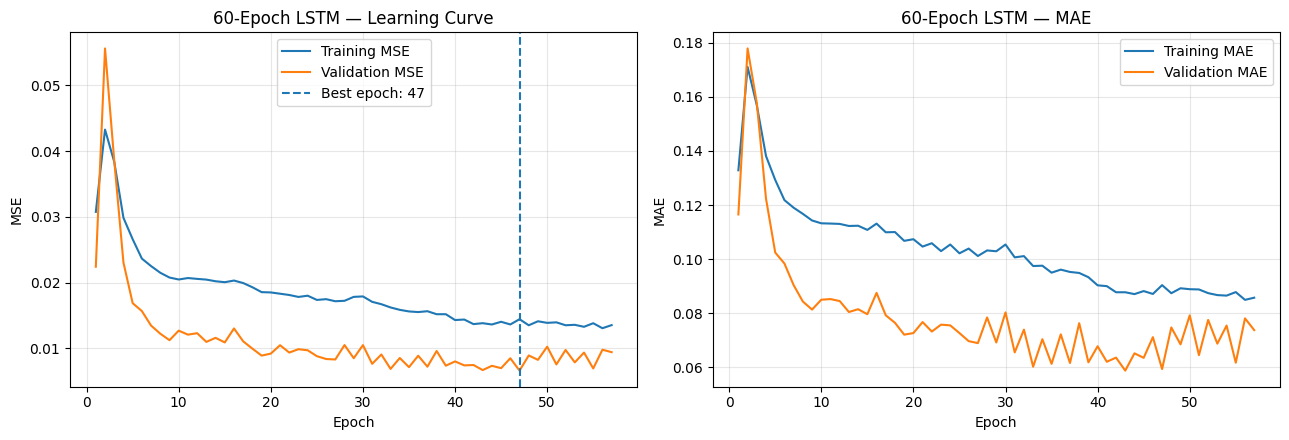

Best epoch: 47
Epochs trained: 57
Training MSE at best epoch: 0.014432
Validation MSE at best epoch: 0.006613


In [13]:

# Plot all 16 trial validation MSE values
trial_order60 = lstm60_trials.sort_values("Trial")

plt.figure(figsize=(11, 4))
plt.bar(
    trial_order60["Trial"].astype(str),
    trial_order60["Validation MSE"]
)
plt.title("LSTM — 60-Epoch Grid Search")
plt.xlabel("Trial Number")
plt.ylabel("Validation MSE (All 7 Outputs)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# Training and validation learning curves
train_loss60 = lstm60_best_history["loss"]
val_loss60 = lstm60_best_history["val_loss"]
train_mae60 = lstm60_best_history["mae"]
val_mae60 = lstm60_best_history["val_mae"]

epochs60 = range(1, len(train_loss60) + 1)
best_epoch60 = int(np.argmin(val_loss60) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(epochs60, train_loss60, label="Training MSE")
axes[0].plot(epochs60, val_loss60, label="Validation MSE")
axes[0].axvline(
    best_epoch60,
    linestyle="--",
    label=f"Best epoch: {best_epoch60}"
)
axes[0].set(
    xlabel="Epoch",
    ylabel="MSE",
    title="60-Epoch LSTM — Learning Curve"
)
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs60, train_mae60, label="Training MAE")
axes[1].plot(epochs60, val_mae60, label="Validation MAE")
axes[1].set(
    xlabel="Epoch",
    ylabel="MAE",
    title="60-Epoch LSTM — MAE"
)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Best epoch:", best_epoch60)
print("Epochs trained:", len(train_loss60))
print("Training MSE at best epoch:",
      round(train_loss60[best_epoch60 - 1], 6))
print("Validation MSE at best epoch:",
      round(val_loss60[best_epoch60 - 1], 6))


VALIDATION PERFORMANCE — ORIGINAL BIKE RENTALS


,Model,MAE (rentals),RMSE (rentals)
0,Naive,738.321101,1059.721960
1,Seasonal Naive,853.321101,1119.552778
2,Mean,3329.242702,3439.299251
3,LSTM (60 Epochs),852.416504,1126.051182



ALL-SEVEN-OUTPUT VALIDATION METRICS
Scaled MSE: 0.006613
Scaled MAE: 0.059325

COMPUTATIONAL COST
Parameters: 18887
Selected trial training time (s): 17.966
Validation inference time (s): 0.0824


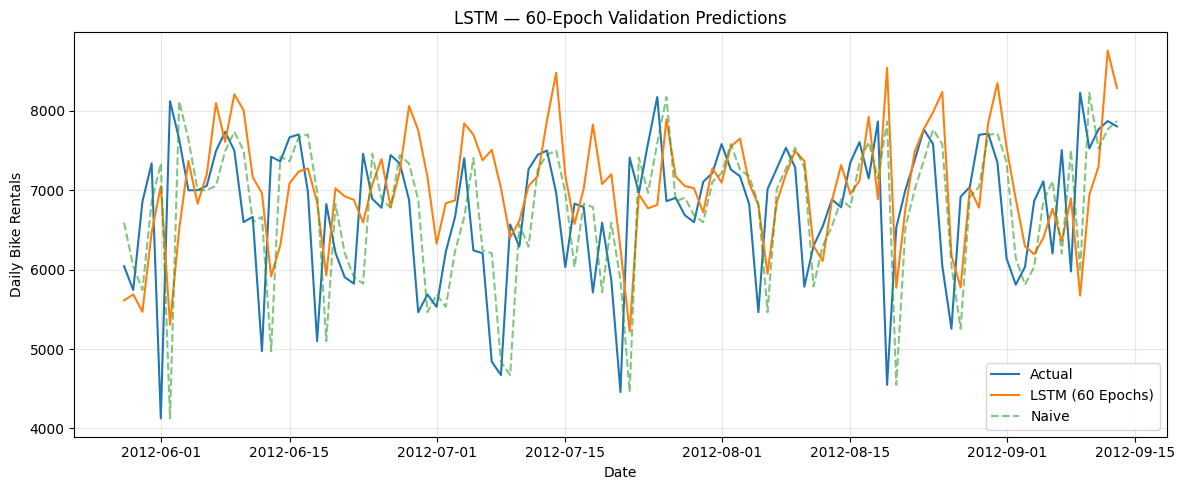

In [14]:

# Compare using the same baseline definitions
# as the original 200-epoch LSTM experiment.

def evaluate_lstm60(X_data, y_data):

    scaled_mse, scaled_mae = lstm60_model.evaluate(
        X_data, y_data, verbose=0
    )

    # Warm-up before measuring inference
    lstm60_model.predict(X_data, verbose=0)

    start = perf_counter()
    predictions = lstm60_model.predict(
        X_data, verbose=0
    )
    inference_time = perf_counter() - start

    actual = inverse_cnt60(y_data[:, 0, 0])

    series = {
        "Naive": inverse_cnt60(X_data[:, -1, 0]),
        "Seasonal Naive": inverse_cnt60(X_data[:, 0, 0]),
        "Mean": inverse_cnt60(
            np.full(len(y_data), y_train[:, 0, 0].mean())
        ),
        "LSTM (60 Epochs)": inverse_cnt60(
            predictions[:, 0, 0]
        )
    }

    rows = []

    for name, predicted in series.items():
        rows.append({
            "Model": name,
            "MAE (rentals)": mean_absolute_error(
                actual, predicted
            ),
            "RMSE (rentals)": np.sqrt(
                mean_squared_error(actual, predicted)
            )
        })

    metrics = pd.DataFrame(rows)

    return metrics, actual, series, scaled_mse, scaled_mae, inference_time


# Validation results
(
    lstm60_val_metrics,
    lstm60_val_actual,
    lstm60_val_series,
    lstm60_val_mse,
    lstm60_val_mae,
    lstm60_val_infer_time
) = evaluate_lstm60(X_val, y_val)

print("VALIDATION PERFORMANCE — ORIGINAL BIKE RENTALS")
display(lstm60_val_metrics)

print("\nALL-SEVEN-OUTPUT VALIDATION METRICS")
print(f"Scaled MSE: {lstm60_val_mse:.6f}")
print(f"Scaled MAE: {lstm60_val_mae:.6f}")

print("\nCOMPUTATIONAL COST")
print("Parameters:", lstm60_model.count_params())
print("Selected trial training time (s):",
      round(lstm60_best_row["Training Time (s)"], 3))
print("Validation inference time (s):",
      round(lstm60_val_infer_time, 4))


# Validation prediction graph
lstm60_val_dates = df.index[L + h - 1:][train_end:val_end]

plt.figure(figsize=(12, 5))
plt.plot(lstm60_val_dates, lstm60_val_actual, label="Actual")
plt.plot(
    lstm60_val_dates,
    lstm60_val_series["LSTM (60 Epochs)"],
    label="LSTM (60 Epochs)"
)
plt.plot(
    lstm60_val_dates,
    lstm60_val_series["Naive"],
    label="Naive",
    linestyle="--",
    alpha=0.6
)

plt.title("LSTM — 60-Epoch Validation Predictions")
plt.xlabel("Date")
plt.ylabel("Daily Bike Rentals")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## LSTM 200 epochs Results and Overfitting Discussion

### 1. Data Preparation

The dataset was transformed into 724 multivariate sliding-window samples using a 7-day lookback and a one-day forecasting horizon. Each input contained 7 variables over 7 consecutive days, giving an input shape of (7, 7).

The data was divided chronologically into 506 training, 109 validation, and 109 testing samples. Log transformations and MinMax scaling were applied using training-fitted scalers to prevent data leakage.

Unlike the MLP, the LSTM retained the three-dimensional input structure to process observations sequentially.

### 2. LSTM Architecture and Grid Search

Grid search was implemented to compare Vanilla and Stacked LSTM architectures with different numbers of LSTM units and learning rates.

Two architectures, two unit sizes, and two learning rates were tested, resulting in **8 configurations**. The model with the lowest validation MSE across all seven scaled output variables was selected.

The best-performing configuration was:

| Hyperparameter | Selected value |
|---|---|
| Architecture | Vanilla LSTM |
| LSTM units | 32 |
| Learning rate | 0.001 |
| Batch size | 32 |
| Dropout | 0.2 |
| Optimizer | Adam |
| Loss function | MSE |
| Trainable parameters | 5,351 |
| Best epoch | 199 |
| Validation MSE | **0.006487** |

The Vanilla LSTM consisted of one LSTM layer with 32 units, followed by a dropout layer and a linear Dense output layer containing 7 neurons.

The grid-search results showed that the Vanilla LSTM configurations generally achieved lower validation errors than the Stacked LSTM configurations. The selected 32-unit Vanilla LSTM achieved the lowest validation MSE of **0.006487**.

This suggests that the simpler architecture was more effective for this dataset within the tested configurations, without requiring the additional complexity of a second LSTM layer.

### 3. Learning Curves and Overfitting Analysis

The training and validation MSE and MAE decreased rapidly during the initial epochs, indicating that the LSTM successfully learned patterns in the data.

The improvement became more gradual as training progressed, with both losses approaching relatively stable values.

The lowest validation MSE occurred at **epoch 199**, with:

- Training MSE: **0.013713**
- Validation MSE: **0.006487**

The validation MSE remained below the training MSE throughout most of training, while both curves continued decreasing without a sustained divergence.

Therefore, **there is no clear evidence of significant overfitting** in the selected LSTM.

The lower validation loss may be related to differences between the chronological training and validation periods, as well as dropout being active during training but inactive during validation.

Training completed all 200 epochs because the early stopping condition of 25 consecutive epochs without improvement was not met. The weights from epoch 199 were restored.

Although the learning curves indicate relatively stable generalization on the validation set, the best epoch occurring near the training limit suggests that additional training could be investigated.

### 4. Validation Performance and Baseline Comparison

The selected LSTM was evaluated on the validation dataset using MAE and RMSE, expressed in original daily bike rental counts.

| Model | Validation MAE | Validation RMSE |
|---|---:|---:|
| Naive | **738.32** | 1059.72 |
| Seasonal Naive | 853.32 | 1119.55 |
| Mean | 3329.24 | 3439.30 |
| LSTM | 760.65 | **945.35** |

The LSTM achieved the lowest validation RMSE of **945.35 rentals**, outperforming all three baselines in this metric.

However, the naive baseline achieved a slightly lower validation MAE of 738.32 rentals compared with the LSTM's 760.65 rentals.

This indicates that the LSTM reduced larger prediction errors more effectively, while the naive baseline had a slightly smaller average absolute error.

### 5. Test Evaluation and Prediction Analysis

The selected LSTM was evaluated on the held-out test dataset, producing:

| Metric | Validation | Test |
|---|---:|---:|
| MAE (rentals) | 760.65 | 1112.50 |
| RMSE (rentals) | 945.35 | 1402.15 |

The test MAE of **1112.50 rentals** indicates that the model's daily rental-count predictions differed from the actual values by approximately 1113 rentals on average.

The test RMSE of **1402.15 rentals** was slightly higher than the naive baseline's RMSE of **1364.93 rentals**.

The actual-versus-predicted graphs show that the LSTM captured general changes in daily bike rentals, but its predictions were noticeably smoother than the actual observations.

During validation, the LSTM followed the overall demand pattern but occasionally underestimated peaks and overestimated sudden decreases.

During testing, the model captured the overall downward trend toward the end of 2012. However, it struggled with abrupt fluctuations, particularly the sharp decrease and recovery in late October.

The naive baseline followed some of these sudden changes more closely, helping explain its slightly better test performance.

The increase in errors from validation to testing suggests that the later period was more difficult to predict. This does not necessarily indicate overfitting, since the chronological test period may contain different demand patterns from the validation period.

### 6. Computational Cost

The selected Vanilla LSTM contained **5,351 trainable parameters**.

The computational performance was:

| Measurement | Result |
|---|---:|
| Training time | 42.50 seconds |
| Validation inference time | 0.1184 seconds |
| Test inference time | 0.1158 seconds |
| Test samples | 109 |

The relatively small architecture provided a manageable computational cost while learning temporal relationships in the bike-sharing dataset.

These measurements can be used to compare the LSTM against the MLP, CNN, RNN, GRU, and TCN models in Stage 2.

### 7. Conclusion

Grid search selected a Vanilla LSTM with 32 units, a learning rate of 0.001, and a batch size of 32 as the best-performing configuration among eight trials.

The model achieved a minimum validation MSE of **0.006487 at epoch 199**, with learning curves showing no clear evidence of significant overfitting.

The LSTM achieved a validation RMSE of **945.35 rentals**, outperforming all three baseline models in that metric. However, its test RMSE of **1402.15 rentals** was slightly higher than the naive baseline's 1364.93 rentals.

Although the LSTM successfully captured general temporal patterns and demand trends, its smoother predictions made it less effective at reproducing sudden fluctuations.

Overall, the results demonstrate that the LSTM is a viable model for forecasting bike-sharing demand, but its additional complexity did not consistently translate into better performance than the simple naive baseline. The validation accuracy, training time, and model complexity provide evidence for the Stage 2 comparison and final model selection.

## LSTM — 60-Epoch Experiment: Results and Discussion

### 1. Hyperparameter Optimization

A single-layer LSTM was trained using the same seven-day sliding windows, one-day forecasting horizon, and chronological train/validation/test splits as the other sequence models.

An exhaustive grid search evaluated 54 hyperparameter combinations. Each configuration was trained for a maximum of 60 epochs, with early stopping patience set to 10 and the best validation weights restored.

The model with the lowest validation MSE across all seven scaled output variables was selected.

| Hyperparameter | Selected value |
|---|---|
| Architecture | Vanilla LSTM |
| LSTM units | 64 |
| Dropout | 0.0 |
| Learning rate | 0.01 |
| Batch size | 16 |
| Maximum epochs | 60 |
| Early stopping patience | 10 |
| Best epoch | 47 |
| Actual epochs trained | 57 |
| Trainable parameters | 18,887 |
| Best validation MSE | **0.006613** |

The selected model had one LSTM layer, followed by a Dense layer and a Reshape layer to produce seven next-day predictions.

### 2. Learning Curves and Overfitting Analysis

The training and validation losses decreased during training, indicating that the model learned temporal patterns from the input sequences.

The best validation MSE of **0.006613** was achieved at epoch 47. The training MSE at this epoch was **0.014432**.

Training continued until epoch 57, when early stopping terminated the run after 10 consecutive epochs without improvement. The weights from epoch 47 were restored.

The validation MSE being lower than the training MSE does not by itself indicate overfitting. However, the higher test error compared with validation suggests that the model did not generalize as effectively to the later chronological period.

### 3. Validation Performance

The optimized LSTM was evaluated using MAE and RMSE in original daily bike rental counts.

| Model | Validation MAE | Validation RMSE |
|---|---:|---:|
| Naive | **738.32** | **1059.72** |
| Seasonal Naive | 853.32 | 1119.55 |
| Mean | 3329.24 | 3439.30 |
| LSTM (60-epoch budget) | 852.42 | 1126.05 |

The LSTM achieved a validation MAE of **852.42 rentals** and RMSE of **1126.05 rentals**.

The naive baseline outperformed the LSTM on both validation metrics, indicating that the recurrent model did not provide a clear predictive advantage over using the previous day's rental count.

### 4. Held-Out Test Performance

The final selected LSTM was evaluated on the held-out test set.

| Model | Test MAE | Test RMSE |
|---|---:|---:|
| Naive | **934.47** | **1364.93** |
| Seasonal Naive | 1380.09 | 1969.52 |
| Mean | 2580.06 | 2893.10 |
| LSTM (60-epoch budget) | 1318.92 | 1677.23 |

The LSTM achieved a test MAE of **1318.92 rentals** and test RMSE of **1677.23 rentals**.

Its scaled test MSE across all seven outputs was **0.025961**, with a scaled MAE of **0.096681**.

Although the LSTM captured broad changes in bike-sharing demand, it was less accurate than the naive baseline on the test set. Its larger RMSE indicates difficulty predicting some of the larger daily fluctuations.

### 5. Computational Cost

| Measurement | Result |
|---|---:|
| Trainable parameters | 18,887 |
| Training time of selected trial | 17.97 seconds |
| Total grid-search time | 598.89 seconds |
| Validation inference time | 0.0824 seconds |
| Test inference time (109 samples) | 0.1109 seconds |
| Test inference time per sample | 1.018 ms |

The selected LSTM used 18,887 trainable parameters and required approximately 18 seconds to train. The complete 54-trial hyperparameter search required approximately 599 seconds.

These values describe the computational cost of the selected model and the overall hyperparameter optimization process.

### 6. Comparison with the Previous 200-Epoch Experiment

| Metric | 60-epoch experiment | 200-epoch experiment |
|---|---:|---:|
| Selected architecture | Vanilla LSTM | Vanilla LSTM |
| LSTM units | 64 | 32 |
| Best epoch | 47 | 199 |
| Validation MSE | 0.006613 | **0.006487** |
| Validation RMSE | 1126.05 | **945.35** |
| Test MAE | 1318.92 | **1112.50** |
| Test RMSE | 1677.23 | **1402.15** |
| Trainable parameters | 18,887 | 5,351 |

The 200-epoch experiment achieved lower validation and test errors despite using fewer trainable parameters.

However, the two experiments used different hyperparameter search spaces and selected different configurations. Therefore, the performance difference cannot be attributed solely to training for more epochs.

The comparison suggests that a larger training budget combined with different hyperparameter choices produced better results in this experiment.

### 7. Conclusion

The 60-epoch LSTM grid search selected a Vanilla LSTM with 64 units, no dropout, a learning rate of 0.01, and batch size 16.

The model achieved a validation MSE of **0.006613** at epoch 47, with a test MAE of **1318.92 rentals** and test RMSE of **1677.23 rentals**.

Although the model learned temporal relationships in the dataset, it did not outperform the naive baseline. The previous 200-epoch LSTM experiment achieved stronger predictive performance, indicating that the training budget and hyperparameter selection both warrant consideration.

Overall, the results demonstrate the importance of evaluating recurrent neural networks against simple forecasting baselines and comparing models using consistent data splits, metrics, and computational-cost measurements.